# Task 2.2: U-Net / Attention U-Net Baseline

This notebook trains a U-Net in pure PyTorch on the CLAHE pipe dataset.


## 1. Environment & reproducibility

In [1]:
!pip install -q torch torchvision albumentations opencv-python-headless matplotlib numpy scikit-learn

import os, glob, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import cv2
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Torch:", torch.__version__, "| Device:", DEVICE)

Torch: 2.11.0+cu128 | Device: cuda


## 2. Data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT  = "/content/drive/MyDrive/Under_Water_Dataset"
MMSEG_ROOT  = os.path.join(DRIVE_ROOT, "Dataset_Processed", "mmseg_pipes")

def list_pairs(split):
    img_dir = os.path.join(MMSEG_ROOT, "images", split)
    ann_dir = os.path.join(MMSEG_ROOT, "annotations", split)
    imgs = sorted(glob.glob(os.path.join(img_dir, "*.png")))
    pairs = [(p, os.path.join(ann_dir, os.path.basename(p))) for p in imgs]
    pairs = [(i, m) for i, m in pairs if os.path.exists(m)]
    return pairs

train_pairs = list_pairs("training")
val_pairs   = list_pairs("validation")
print(f"train: {len(train_pairs)} | val: {len(val_pairs)}")
assert train_pairs, "No training pairs found — run Task 1.2 (mmseg_pipes) first."

Mounted at /content/drive
train: 84 | val: 21


### 2.1 Dataset & augmentation

In [3]:
import albumentations as A

IMG_SIZE = 512

train_tf = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(0.1, 0.1, p=0.3),
])
val_tf = A.Compose([A.Resize(IMG_SIZE, IMG_SIZE)])

class PipeDataset(Dataset):
    def __init__(self, pairs, tf):
        self.pairs, self.tf = pairs, tf
    def __len__(self): return len(self.pairs)
    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 0).astype(np.uint8)
        out = self.tf(image=img, mask=mask)
        img, mask = out["image"], out["mask"]
        img = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
        mask = torch.from_numpy(mask).long()
        return img, mask

BATCH = 4
train_ds = PipeDataset(train_pairs, train_tf)
val_ds   = PipeDataset(val_pairs, val_tf)
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2)
print("Batches — train:", len(train_dl), "| val:", len(val_dl))

Batches — train: 21 | val: 6


## 3. Model

In [4]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.block(x)

class AttentionGate(nn.Module):

    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(f_g, f_int, 1), nn.BatchNorm2d(f_int))
        self.W_x = nn.Sequential(nn.Conv2d(f_l, f_int, 1), nn.BatchNorm2d(f_int))
        self.psi = nn.Sequential(nn.Conv2d(f_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
    def forward(self, g, x):
        g1, x1 = self.W_g(g), self.W_x(x)
        psi = self.psi(self.relu(g1 + x1))
        return x * psi

class UNet(nn.Module):
    def __init__(self, in_ch=3, n_classes=2, feats=(64,128,256,512), attention=False):
        super().__init__()
        self.attention = attention
        self.downs = nn.ModuleList()
        self.ups   = nn.ModuleList()
        self.gates = nn.ModuleList()
        self.pool  = nn.MaxPool2d(2)
        c = in_ch
        for f in feats:
            self.downs.append(DoubleConv(c, f)); c = f
        self.bottleneck = DoubleConv(feats[-1], feats[-1]*2)
        for f in reversed(feats):
            self.ups.append(nn.ConvTranspose2d(f*2, f, 2, stride=2))
            if attention: self.gates.append(AttentionGate(f, f, f//2))
            self.ups.append(DoubleConv(f*2, f))
        self.final = nn.Conv2d(feats[0], n_classes, 1)
    def forward(self, x):
        skips = []
        for d in self.downs:
            x = d(x); skips.append(x); x = self.pool(x)
        x = self.bottleneck(x)
        skips = skips[::-1]
        for i in range(0, len(self.ups), 2):
            x = self.ups[i](x)
            skip = skips[i//2]
            if x.shape[-2:] != skip.shape[-2:]:
                x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            if self.attention:
                skip = self.gates[i//2](x, skip)
            x = torch.cat([skip, x], dim=1)
            x = self.ups[i+1](x)
        return self.final(x)

# Toggle the variant to train
USE_ATTENTION = False
model = UNet(n_classes=2, attention=USE_ATTENTION).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{'Attention U-Net' if USE_ATTENTION else 'U-Net'} — {n_params/1e6:.2f}M params")

U-Net — 31.04M params


## 4. Losses and metrics

Combined CrossEntropy + Dice loss handles the strong class imbalance.

In [5]:
def dice_loss(logits, target, eps=1e-6):
    probs = F.softmax(logits, dim=1)[:, 1]
    t = (target == 1).float()
    inter = (probs * t).sum(dim=(1,2))
    union = probs.sum(dim=(1,2)) + t.sum(dim=(1,2))
    return 1 - ((2*inter + eps) / (union + eps)).mean()

ce = nn.CrossEntropyLoss()
def criterion(logits, target):
    return ce(logits, target) + dice_loss(logits, target)

@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    iou_pipe, dice_pipe, n = 0.0, 0.0, 0
    for img, mask in dl:
        img, mask = img.to(DEVICE), mask.to(DEVICE)
        pred = model(img).argmax(1)
        p, t = (pred == 1), (mask == 1)
        inter = (p & t).sum((1,2)).float()
        union = (p | t).sum((1,2)).float().clamp(min=1)
        iou_pipe  += (inter / union).sum().item()
        dice_pipe += ((2*inter) / (p.sum((1,2))+t.sum((1,2))).clamp(min=1).float()).sum().item()
        n += img.size(0)
    return iou_pipe/n, dice_pipe/n

## 5. Training loop

In [6]:
EPOCHS = 40
LR = 1e-4
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

history = {"train_loss": [], "val_miou": [], "val_dice": []}
best_dice, best_state = 0.0, None

for epoch in range(1, EPOCHS+1):
    model.train(); running = 0.0
    for img, mask in train_dl:
        img, mask = img.to(DEVICE), mask.to(DEVICE)
        opt.zero_grad()
        loss = criterion(model(img), mask)
        loss.backward(); opt.step()
        running += loss.item()
    sched.step()
    tr_loss = running / len(train_dl)
    miou, dice = evaluate(model, val_dl)
    history["train_loss"].append(tr_loss)
    history["val_miou"].append(miou)
    history["val_dice"].append(dice)
    if dice > best_dice:
        best_dice, best_state = dice, {k: v.cpu() for k, v in model.state_dict().items()}
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | loss {tr_loss:.4f} | val mIoU(pipe) {miou:.4f} | val Dice(pipe) {dice:.4f}")

print(f"\nBest val Dice(pipe): {best_dice:.4f}")

Epoch   1 | loss 1.1208 | val mIoU(pipe) 0.7025 | val Dice(pipe) 0.7485
Epoch   5 | loss 0.8916 | val mIoU(pipe) 0.6463 | val Dice(pipe) 0.7061
Epoch  10 | loss 0.8563 | val mIoU(pipe) 0.6715 | val Dice(pipe) 0.7245
Epoch  15 | loss 0.8543 | val mIoU(pipe) 0.6794 | val Dice(pipe) 0.7312
Epoch  20 | loss 0.8575 | val mIoU(pipe) 0.6872 | val Dice(pipe) 0.7366
Epoch  25 | loss 0.8261 | val mIoU(pipe) 0.6591 | val Dice(pipe) 0.7108
Epoch  30 | loss 0.8378 | val mIoU(pipe) 0.6912 | val Dice(pipe) 0.7388
Epoch  35 | loss 0.8194 | val mIoU(pipe) 0.6849 | val Dice(pipe) 0.7331
Epoch  40 | loss 0.8132 | val mIoU(pipe) 0.6777 | val Dice(pipe) 0.7270

Best val Dice(pipe): 0.7485


## 6. Curves — loss and validation metrics

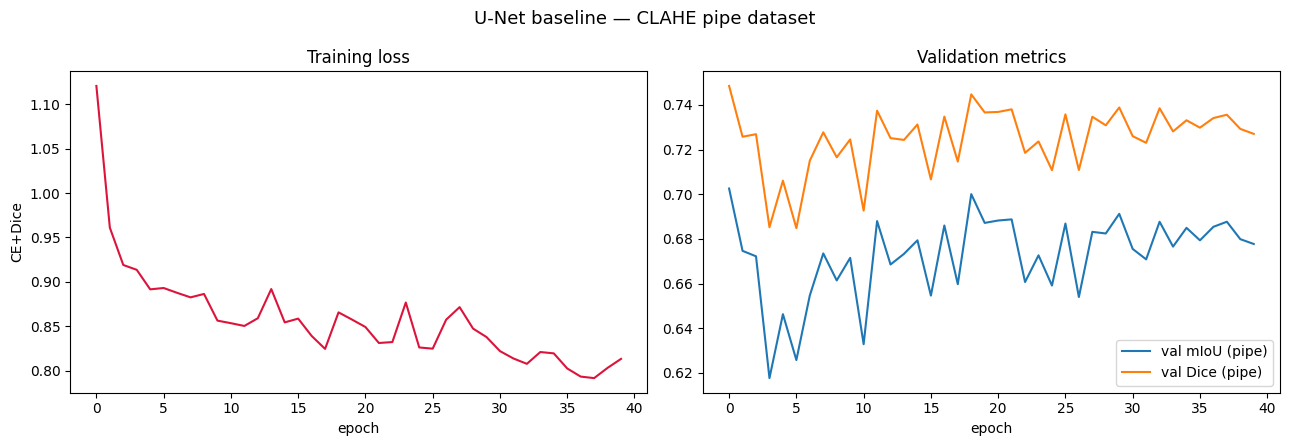

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history["train_loss"], color="crimson")
axes[0].set_title("Training loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("CE+Dice")
axes[1].plot(history["val_miou"], label="val mIoU (pipe)")
axes[1].plot(history["val_dice"], label="val Dice (pipe)")
axes[1].set_title("Validation metrics"); axes[1].set_xlabel("epoch"); axes[1].legend()
variant = "Attention U-Net" if USE_ATTENTION else "U-Net"
plt.suptitle(f"{variant} baseline — CLAHE pipe dataset", fontsize=13)
plt.tight_layout(); plt.show()

## 7. Qualitative predictions

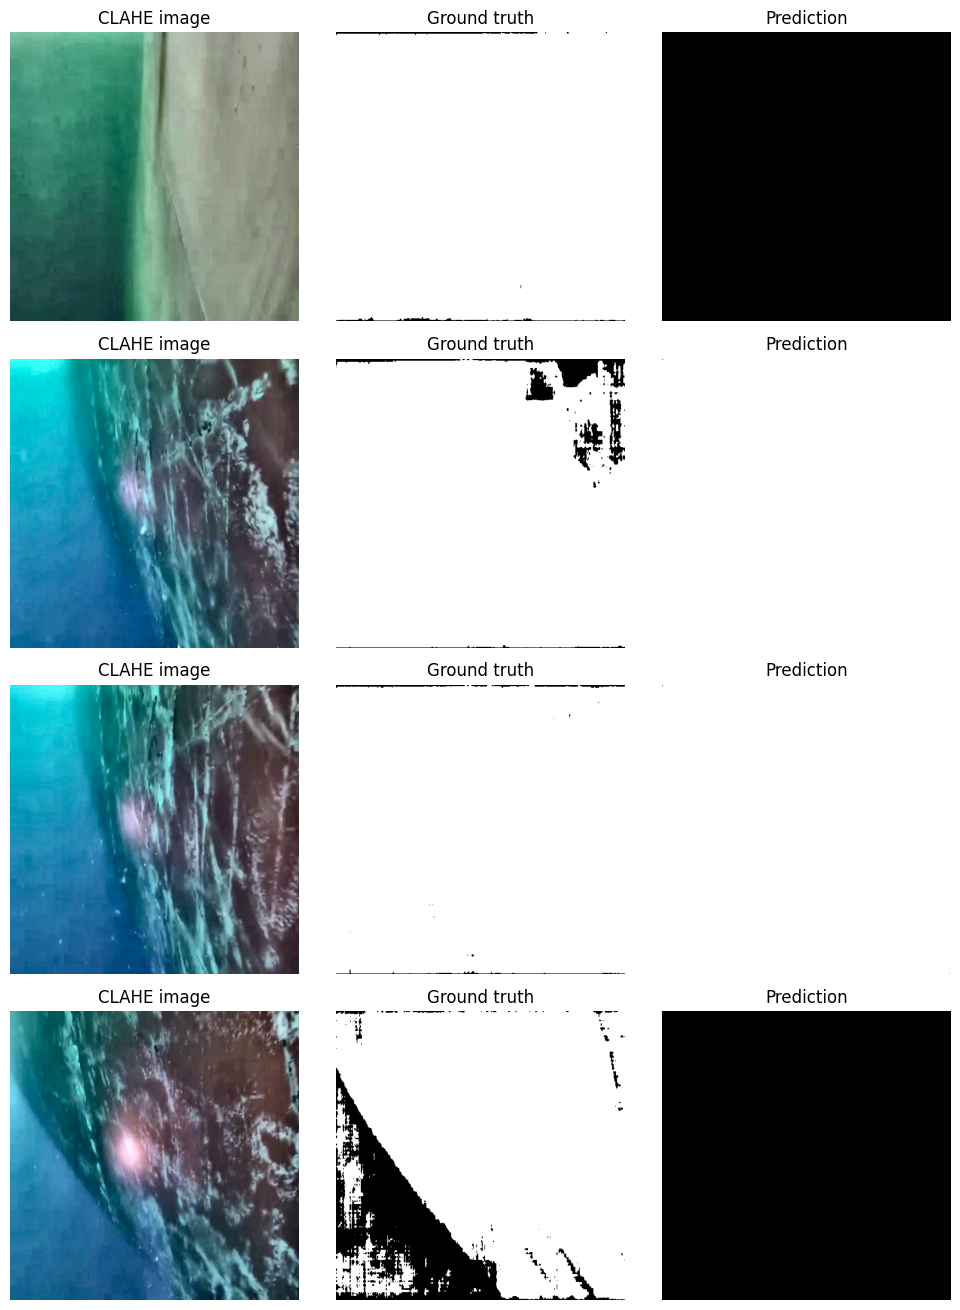

In [8]:
if best_state: model.load_state_dict(best_state)
model.eval()

imgs, masks = next(iter(val_dl))
with torch.no_grad():
    preds = model(imgs.to(DEVICE)).argmax(1).cpu()

n = min(4, imgs.size(0))
fig, axes = plt.subplots(n, 3, figsize=(10, 3.3*n))
if n == 1: axes = axes.reshape(1, 3)
for i in range(n):
    axes[i,0].imshow(imgs[i].permute(1,2,0)); axes[i,0].set_title("CLAHE image"); axes[i,0].axis("off")
    axes[i,1].imshow(masks[i], cmap="gray");  axes[i,1].set_title("Ground truth"); axes[i,1].axis("off")
    axes[i,2].imshow(preds[i], cmap="gray");  axes[i,2].set_title("Prediction");   axes[i,2].axis("off")
plt.tight_layout(); plt.show()

## 8. Save weights + metrics summary

In [9]:
import json
OUT_DIR = os.path.join(DRIVE_ROOT, "Dataset_Processed", "unet_baseline")
os.makedirs(OUT_DIR, exist_ok=True)

tag = "attn_unet" if USE_ATTENTION else "unet"
torch.save(best_state, os.path.join(OUT_DIR, f"{tag}_best.pth"))

summary = {
    "variant": "Attention U-Net" if USE_ATTENTION else "U-Net",
    "params_millions": round(n_params/1e6, 2),
    "epochs": EPOCHS, "img_size": IMG_SIZE, "batch": BATCH, "lr": LR,
    "best_val_dice_pipe": round(best_dice, 4),
    "final_val_miou_pipe": round(history["val_miou"][-1], 4),
    "n_train": len(train_pairs), "n_val": len(val_pairs),
}
with open(os.path.join(OUT_DIR, f"{tag}_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("\nSaved to:", OUT_DIR)

{
  "variant": "U-Net",
  "params_millions": 31.04,
  "epochs": 40,
  "img_size": 512,
  "batch": 4,
  "lr": 0.0001,
  "best_val_dice_pipe": 0.7485,
  "final_val_miou_pipe": 0.6777,
  "n_train": 84,
  "n_val": 21
}

Saved to: /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/unet_baseline
